# VoltAhead — Charging Patterns & Temporal Usage Analysis

## Step 1: Exploratory Data Analysis (EDA)

**Objective:** Analyze temporal charging station occupancy patterns in the UrbanEV dataset, including hourly, daily, weekly, and monthly variations.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("VoltAhead environment is ready!")

VoltAhead environment is ready!


In [56]:
from pathlib import Path

print("Current directory:", Path.cwd())

data_path = Path("../data")

print("Data folder exists:", data_path.exists())

if data_path.exists():
    for item in list(data_path.iterdir())[:20]:
        print(item.name)

Current directory: /Users/zumra/Desktop/classes/26-27/fall 2026/ISE308/VoltAhead/notebooks
Data folder exists: True
VoltAhead_Dataset.zip
.DS_Store
selected_stations.csv
.gitkeep
selected_stations_data.csv
.cache


In [57]:
PROJECT_ROOT = Path.cwd().parent

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Output folders are ready!")

Output folders are ready!


## Data Loading & Initial Verification

Load the shared VoltAhead dataset and verify the number of stations, observations, and temporal coverage.

In [58]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_loader as dl

df = dl.load_data()

print("Dataset shape:", df.shape)
print(
    "Number of stations:",
    df.index.get_level_values("station_id").nunique()
)
print(
    "Time range:",
    df.index.get_level_values("time").min(),
    "to",
    df.index.get_level_values("time").max()
)

display(df.head())

Dataset shape: (2592000, 10)
Number of stations: 100
Time range: 2022-12-01 00:00:00 to 2023-02-28 23:55:00


busy  idle  s_price  e_price  fast_busy  \
station_id time                                                           
1703       2022-12-01 00:00:00   0.0   2.0     0.76     0.74        0.0   
           2022-12-01 00:05:00   0.0   2.0     0.76     0.74        0.0   
           2022-12-01 00:10:00   0.0   2.0     0.76     0.74        0.0   
           2022-12-01 00:15:00   0.0   2.0     0.76     0.74        0.0   
           2022-12-01 00:20:00   0.0   2.0     0.76     0.74        0.0   

                                fast_idle  slow_busy  slow_idle  duration  \
station_id time                                                             
1703       2022-12-01 00:00:00        0.0        0.0        2.0       0.0   
           2022-12-01 00:05:00        0.0        0.0        2.0       0.0   
           2022-12-01 00:10:00        0.0        0.0        2.0       0.0   
           2022-12-01 00:15:00        0.0        0.0        2.0       0.0   
           2022-12-01 00:20:00        0.0        0.0        2.0       0.0   

                                volume  
station_id time                         
1703       2022-12-01 00:00:00     0.0  
           2022-12-01 00:05:00     0.0  
           2022-12-01 00:10:00     0.0  
           2022-12-01 00:15:00     0.0  
           2022-12-01 00:20:00     0.0

## 1. Hourly Occupancy Analysis

**Objective:** Analyze how the average occupancy rate of EV charging stations changes throughout the day and identify peak and off-peak charging hours.

In [59]:
# Attach station capacity information
df_analysis = dl.attach_station_info(df)

# Check occupancy data consistency
valid = (
    df_analysis["busy"].notna()
    & df_analysis["idle"].notna()
    & (df_analysis["busy"] >= 0)
    & (df_analysis["idle"] >= 0)
    & (df_analysis["charge_count"] > 0)
)

valid_df = df_analysis.loc[valid].copy()

capacity_mismatch = (
    (valid_df["busy"] + valid_df["idle"])
    != valid_df["charge_count"]
)

print("Total observations:", len(df_analysis))
print("Valid observations:", len(valid_df))
print("Capacity mismatches:", capacity_mismatch.sum())
print("Mismatch percentage:",
      round(capacity_mismatch.mean() * 100, 2), "%")

Total observations: 2592000
Valid observations: 1931984
Capacity mismatches: 0
Mismatch percentage: 0.0 %


In [60]:
# Calculate occupancy rate
valid_df["occupancy_rate"] = (
    valid_df["busy"] / valid_df["charge_count"]
)

# Extract hour from timestamp
valid_df["hour"] = (
    valid_df.index.get_level_values("time").hour
)

# Calculate average occupancy for each hour
hourly_occupancy = (
    valid_df.groupby("hour")["occupancy_rate"]
    .mean()
    .reindex(range(24))
)

# Prepare hourly occupancy table
hourly_table = (
    (hourly_occupancy * 100)
    .round(2)
    .to_frame("Average Occupancy (%)")
)

# Display table
display(hourly_table)

# Save table as CSV
hourly_table.to_csv(
    TABLES_DIR / "hourly_occupancy.csv"
)

,Average Occupancy (%)
hour,
0,18.45
1,18.46
2,18.40
3,18.35
4,18.36
5,18.36
6,18.36
7,18.12
8,18.77


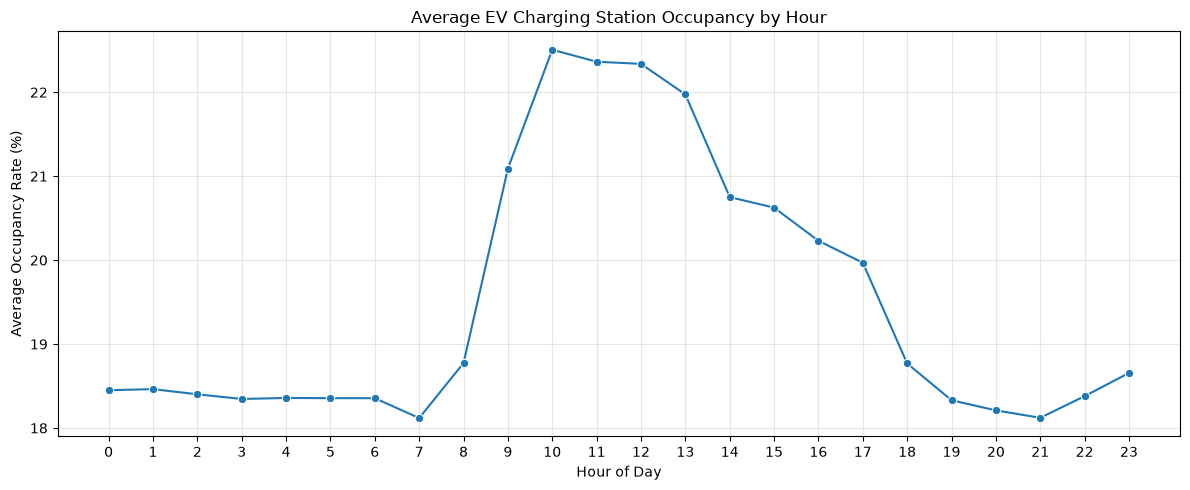

In [61]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_occupancy.index,
    y=hourly_occupancy.values * 100,
    marker="o"
)

plt.title("Average EV Charging Station Occupancy by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Occupancy Rate (%)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hourly_occupancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Hourly Occupancy

The average occupancy rate varies throughout the day, with a noticeable increase during morning hours.

Occupancy rises sharply after 08:00 and reaches its maximum of **22.51% at 10:00**. Elevated occupancy levels continue until approximately 13:00, followed by a gradual decrease.

The lowest hourly averages are observed around 07:00 and 21:00, at approximately **18.12%**.

**ML Implication:** Hour of day is a potentially useful feature for predicting future charger availability, as charging station utilization exhibits a clear temporal pattern.

## 2. Day of Week Occupancy Analysis

In [62]:
# Extract day of week (Monday=0, Sunday=6)
valid_df["day_of_week"] = (
    valid_df.index.get_level_values("time").day_of_week
)

day_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Average occupancy rate by day of week
daily_occupancy = (
    valid_df.groupby("day_of_week")["occupancy_rate"]
    .mean()
    .reindex(range(7))
)

# Prepare daily occupancy table
daily_results = pd.DataFrame({
    "Day": day_names,
    "Average Occupancy (%)": (daily_occupancy.values * 100).round(2)
})

# Display table
display(daily_results)

# Save table as CSV
daily_results.to_csv(
    TABLES_DIR / "daily_occupancy.csv",
    index=False
)

,Day,Average Occupancy (%)
0,Monday,20.62
1,Tuesday,19.60
2,Wednesday,19.54
3,Thursday,19.71
4,Friday,20.66
5,Saturday,18.12
6,Sunday,18.24


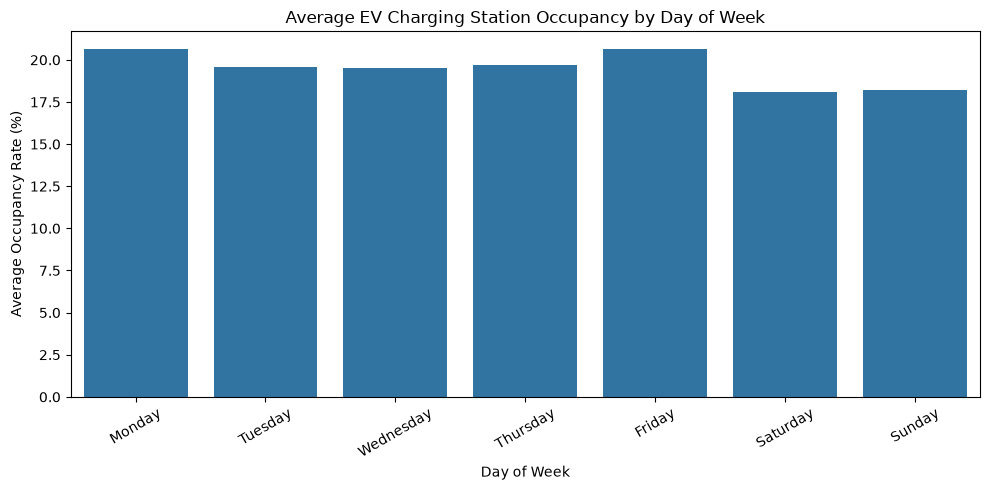

In [63]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_results["Day"],
    y=daily_results["Average Occupancy (%)"]
)

plt.title("Average EV Charging Station Occupancy by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Occupancy Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "daily_occupancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Day of Week Occupancy

The average occupancy rate varies across the days of the week.

Friday has the highest average occupancy rate (**20.66%**), followed closely by Monday (**20.62%**). Saturday has the lowest average occupancy rate (**18.12%**).

Occupancy tends to be higher on weekdays than on weekends, suggesting a possible relationship between charging demand and weekly activity patterns.

**ML Implication:** Day of week may be a useful feature for predicting future charging station availability.

## 3. Weekday vs. Weekend Comparison

In [64]:
# Classify observations as Weekday or Weekend
valid_df["day_type"] = np.where(
    valid_df["day_of_week"] < 5,
    "Weekday",
    "Weekend"
)

# Calculate average occupancy and observation counts
day_type_occupancy = (
    valid_df.groupby("day_type")["occupancy_rate"]
    .agg(["mean", "count"])
    .reindex(["Weekday", "Weekend"])
)

# Convert occupancy rate to percentage
day_type_occupancy["mean"] = (
    day_type_occupancy["mean"] * 100
)

# Rename columns
day_type_occupancy = day_type_occupancy.rename(
    columns={
        "mean": "Average Occupancy (%)",
        "count": "Valid Observations"
    }
)

# Display table
display(day_type_occupancy.round(2))

# Save table as CSV
day_type_occupancy.round(2).to_csv(
    TABLES_DIR / "weekday_vs_weekend.csv"
)

,Average Occupancy (%),Valid Observations
day_type,,
Weekday,20.03,1373843
Weekend,18.18,558141


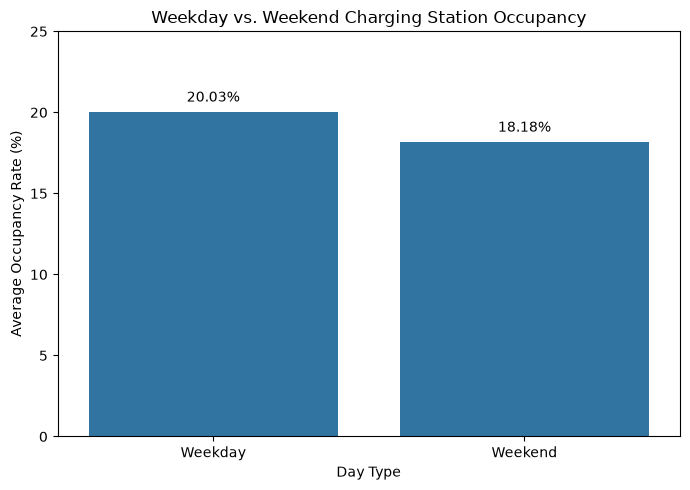

In [65]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=day_type_occupancy.index,
    y=day_type_occupancy["Average Occupancy (%)"]
)

plt.title("Weekday vs. Weekend Charging Station Occupancy")
plt.xlabel("Day Type")
plt.ylabel("Average Occupancy Rate (%)")
plt.ylim(0, 25)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "weekday_vs_weekend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Weekday vs. Weekend

The average occupancy rate is **20.03% on weekdays** and **18.18% on weekends**, representing a difference of **1.85 percentage points**.

This indicates that charging stations in the selected dataset generally experience higher occupancy during weekdays.

The analysis includes 1,373,843 valid weekday observations and 558,141 valid weekend observations.

**ML Implication:** A weekday/weekend indicator may help the prediction model capture differences in charging station utilization patterns.

## 4. Peak and Off-Peak Hours

In [66]:
# Identify top 5 peak hours
peak_hours = hourly_occupancy.nlargest(5)

# Identify top 5 off-peak hours
off_peak_hours = hourly_occupancy.nsmallest(5)

# Prepare tables with occupancy percentages
peak_table = (
    (peak_hours * 100)
    .round(2)
    .to_frame("Average Occupancy (%)")
)

off_peak_table = (
    (off_peak_hours * 100)
    .round(2)
    .to_frame("Average Occupancy (%)")
)

# Display tables
print("Top 5 Peak Hours:")
display(peak_table)

print("Top 5 Off-Peak Hours:")
display(off_peak_table)

# Save tables as CSV
peak_table.to_csv(
    TABLES_DIR / "peak_hours.csv"
)

off_peak_table.to_csv(
    TABLES_DIR / "off_peak_hours.csv"
)

Top 5 Peak Hours:


,Average Occupancy (%)
hour,
10,22.51
11,22.36
12,22.34
13,21.97
9,21.09


Top 5 Off-Peak Hours:


,Average Occupancy (%)
hour,
7,18.12
21,18.12
20,18.21
19,18.33
3,18.35


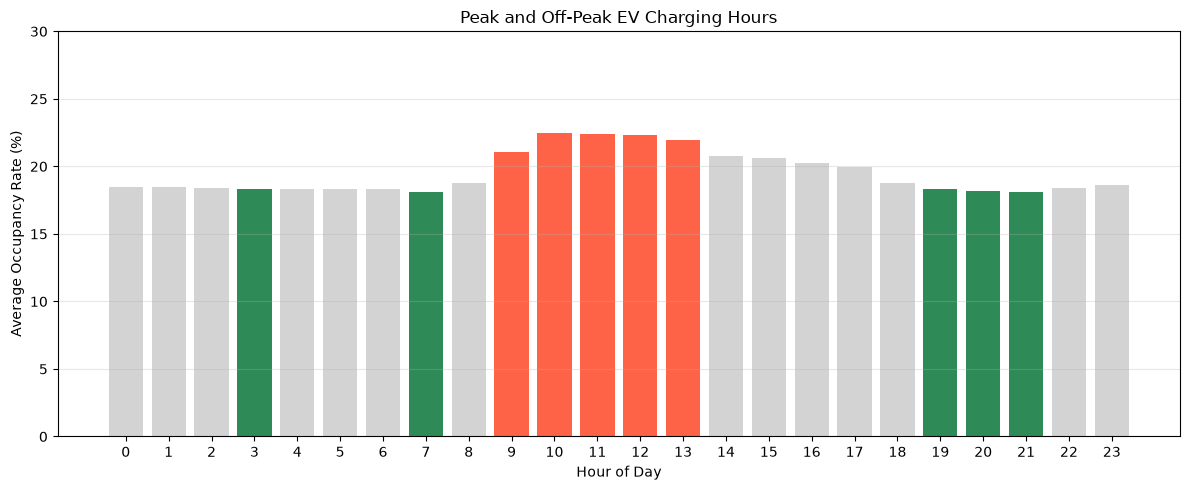

In [67]:
# Visualize peak and off-peak hours

hourly_pct = hourly_occupancy * 100

colors = [
    "tomato" if h in peak_hours.index
    else "seagreen" if h in off_peak_hours.index
    else "lightgray"
    for h in hourly_pct.index
]

plt.figure(figsize=(12, 5))

plt.bar(hourly_pct.index, hourly_pct.values, color=colors)

plt.title("Peak and Off-Peak EV Charging Hours")
plt.xlabel("Hour of Day")
plt.ylabel("Average Occupancy Rate (%)")
plt.xticks(range(24))
plt.ylim(0, 30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "peak_offpeak_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Peak and Off-Peak Hours

The highest average occupancy rates occur between **09:00 and 13:59**, with a maximum of **22.51% at 10:00**.

The five lowest-occupancy hours are 03:00, 07:00, 19:00, 20:00, and 21:00. The lowest hourly averages are approximately **18.12%**.

These results indicate that the selected charging stations experience relatively higher occupancy during late morning and early afternoon.

**ML Implication:** Identifying peak and off-peak periods supports the use of time-based features in future charger availability prediction models.

## 5. Monthly Occupancy Trends

In [68]:
# Extract month from timestamp
valid_df["month"] = (
    valid_df.index.get_level_values("time")
    .to_period("M")
    .astype(str)
)

# Calculate monthly occupancy and valid observation counts
monthly_occupancy = (
    valid_df.groupby("month")["occupancy_rate"]
    .agg(["mean", "count"])
)

# Convert occupancy rate to percentage
monthly_occupancy["mean"] = (
    monthly_occupancy["mean"] * 100
)

# Rename columns
monthly_occupancy = monthly_occupancy.rename(
    columns={
        "mean": "Average Occupancy (%)",
        "count": "Valid Observations"
    }
)

# Display table
display(monthly_occupancy.round(2))

# Save table as CSV
monthly_occupancy.round(2).to_csv(
    TABLES_DIR / "monthly_occupancy.csv"
)

,Average Occupancy (%),Valid Observations
month,,
2022-12,19.99,807926
2023-01,18.39,693629
2023-02,20.34,430429


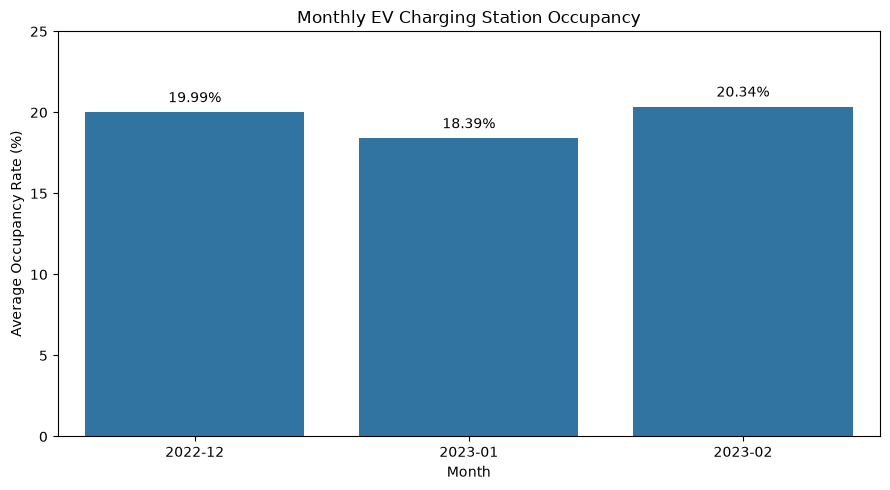

In [69]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=monthly_occupancy.index,
    y=monthly_occupancy["Average Occupancy (%)"]
)

plt.title("Monthly EV Charging Station Occupancy")
plt.xlabel("Month")
plt.ylabel("Average Occupancy Rate (%)")
plt.ylim(0, 25)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_occupancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
# Get actual number of stations
n_stations = df.index.get_level_values("station_id").nunique()

# Expected observations per month
expected_per_month = {
    "2022-12": n_stations * 31 * 288,
    "2023-01": n_stations * 31 * 288,
    "2023-02": n_stations * 28 * 288
}

# Calculate monthly data coverage
coverage = monthly_occupancy[["Valid Observations"]].copy()

coverage["Expected Observations"] = pd.Series(expected_per_month)

coverage["Data Coverage (%)"] = (
    coverage["Valid Observations"]
    / coverage["Expected Observations"]
    * 100
)

# Display table
display(coverage.round(2))

# Save table as CSV
coverage.round(2).to_csv(
    TABLES_DIR / "monthly_data_coverage.csv"
)

,Valid Observations,Expected Observations,Data Coverage (%)
month,,,
2022-12,807926,892800,90.49
2023-01,693629,892800,77.69
2023-02,430429,806400,53.38


### Key Findings — Monthly Occupancy Trends

The average occupancy rate was 19.99% in December 2022, decreased to 18.39% in January 2023, and increased to 20.34% in February 2023.

However, data coverage decreased substantially across the observation period, from approximately 90.49% in December to 53.38% in February.

Therefore, the observed monthly differences should be interpreted cautiously, as missing observations may influence the calculated averages.

**ML Implication:** Temporal features may help capture changes in charging station usage, but missing-data patterns must be considered during model development and evaluation.

## 6. Fast vs. Slow Charger Comparison

**Objective:** Compare the average occupancy rates of fast and slow charging points to identify differences in their utilization patterns.

In [71]:
# Filter valid fast charger observations
fast_valid = valid_df[
    (valid_df["fast_count"] > 0)
    & valid_df["fast_busy"].notna()
    & (valid_df["fast_busy"] >= 0)
    & (valid_df["fast_busy"] <= valid_df["fast_count"])
].copy()

# Filter valid slow charger observations
slow_valid = valid_df[
    (valid_df["slow_count"] > 0)
    & valid_df["slow_busy"].notna()
    & (valid_df["slow_busy"] >= 0)
    & (valid_df["slow_busy"] <= valid_df["slow_count"])
].copy()

# Calculate occupancy rates
fast_valid["fast_occupancy_rate"] = (
    fast_valid["fast_busy"] / fast_valid["fast_count"]
)

slow_valid["slow_occupancy_rate"] = (
    slow_valid["slow_busy"] / slow_valid["slow_count"]
)

# Prepare charger comparison table
charger_comparison = pd.DataFrame({
    "Charger Type": ["Fast", "Slow"],
    "Average Occupancy (%)": [
        fast_valid["fast_occupancy_rate"].mean() * 100,
        slow_valid["slow_occupancy_rate"].mean() * 100
    ],
    "Valid Observations": [
        len(fast_valid),
        len(slow_valid)
    ]
})

# Display table
display(charger_comparison.round(2))

# Save table as CSV
charger_comparison.round(2).to_csv(
    TABLES_DIR / "charger_comparison.csv",
    index=False
)

,Charger Type,Average Occupancy (%),Valid Observations
0,Fast,49.05,9063
1,Slow,19.50,1931984


In [72]:
station_info = dl.load_station_info()

print("Total stations:", len(station_info))

print(
    "Stations with fast chargers:",
    (station_info["fast_count"] > 0).sum()
)

print(
    "Stations with slow chargers:",
    (station_info["slow_count"] > 0).sum()
)

print(
    "Total fast chargers:",
    station_info["fast_count"].sum()
)

print(
    "Total slow chargers:",
    station_info["slow_count"].sum()
)

Total stations: 100
Stations with fast chargers: 1
Stations with slow chargers: 100
Total fast chargers: 2
Total slow chargers: 1064


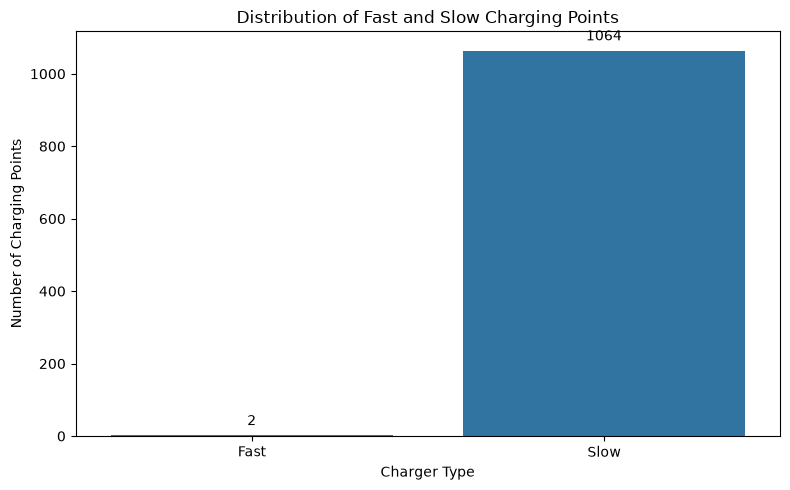

In [73]:
charger_counts = pd.DataFrame({
    "Charger Type": ["Fast", "Slow"],
    "Number of Charging Points": [
        station_info["fast_count"].sum(),
        station_info["slow_count"].sum()
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=charger_counts,
    x="Charger Type",
    y="Number of Charging Points"
)

plt.title("Distribution of Fast and Slow Charging Points")
plt.xlabel("Charger Type")
plt.ylabel("Number of Charging Points")

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "charger_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Fast vs. Slow Chargers

The selected dataset contains **1,064 slow charging points across 100 stations**, while only **2 fast charging points are available at one station**.

The observed average occupancy rates are 49.05% for fast chargers and 19.50% for slow chargers.

However, the comparison is highly unbalanced. The fast charger occupancy rate is derived from only one station and cannot be generalized to the overall charging network.

**ML Implication:** Due to the limited representation of fast chargers, the initial prediction models should prioritize overall station occupancy and temporal features rather than charger-type-specific patterns.

## 7. Day-Hour Occupancy Heatmap

**Objective:** Visualize how average EV charging station occupancy varies across different days of the week and hours of the day, identifying combined temporal usage patterns.

In [74]:
# Calculate average occupancy by day of week and hour
day_hour_occupancy = (
    valid_df.groupby(["day_of_week", "hour"])["occupancy_rate"]
    .mean()
    .unstack("hour")
    .reindex(index=range(7), columns=range(24))
)

# Convert occupancy rates to percentages
day_hour_pct = day_hour_occupancy * 100

# Label days of the week
day_hour_pct.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Prepare day-hour occupancy table
day_hour_table = day_hour_pct.round(2)

# Display table
display(day_hour_table)

# Save table as CSV
day_hour_table.to_csv(
    TABLES_DIR / "day_hour_occupancy.csv"
)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Monday,19.40,19.00,19.12,19.16,19.23,19.19,19.12,18.76,19.82,22.98,...,23.39,22.79,22.26,21.68,19.69,18.93,18.45,18.17,18.44,18.52
Tuesday,18.51,18.58,18.46,18.22,18.19,18.31,18.38,18.17,18.65,21.25,...,21.98,21.74,21.13,20.53,18.65,18.03,17.81,17.78,17.94,18.11
Wednesday,17.09,17.83,17.85,17.84,17.90,17.88,17.97,17.61,18.74,21.95,...,21.88,21.89,21.29,20.47,18.54,18.19,17.99,17.72,17.85,18.05
Thursday,18.53,18.35,17.97,17.87,17.88,17.84,17.82,17.56,18.56,21.42,...,21.37,22.01,21.20,21.02,19.57,18.83,18.75,18.52,19.03,19.33
Friday,18.34,18.47,18.30,18.34,18.30,18.29,18.23,18.15,19.54,23.86,...,21.66,21.29,20.81,20.38,18.80,18.29,18.15,18.20,18.39,19.14
Saturday,18.30,18.13,18.24,18.10,18.10,18.09,18.05,17.71,17.32,17.57,...,17.77,18.00,17.97,18.17,18.28,18.28,18.38,18.27,18.50,18.64
Sunday,18.96,18.86,18.85,18.90,18.92,18.90,18.93,18.90,18.83,18.66,...,17.33,16.87,17.14,17.65,17.86,17.74,17.89,18.15,18.43,18.71


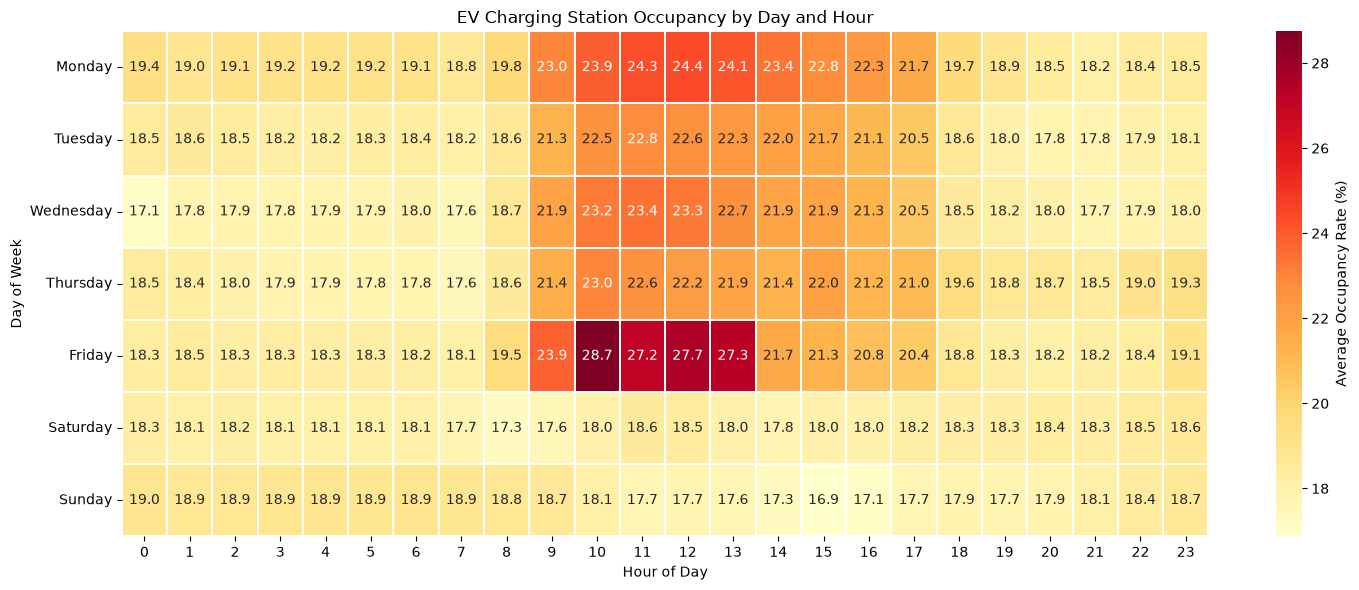

In [75]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    day_hour_pct,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "Average Occupancy Rate (%)"}
)

plt.title("EV Charging Station Occupancy by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "day_hour_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings — Day-Hour Occupancy Heatmap

The heatmap reveals clear differences in charging station occupancy across days and hours.

The highest observed average occupancy occurs on **Friday at 10:00 (approximately 28.7%)**, while the lowest occurs on **Sunday at 15:00 (approximately 16.9%)**.

Weekdays show a noticeable increase in occupancy between 09:00 and 13:00, particularly on Fridays. In contrast, weekend occupancy remains relatively low and stable.

These findings suggest that the combination of hour of day and day of week may help capture charging station utilization patterns more effectively than considering either variable alone.

**ML Implication:** Hour of day and day of week should be considered as predictive features. Their interaction may also provide useful information for future charger availability prediction.

### 8. Conclusion

The Charging Patterns & Temporal Usage Analysis revealed clear hourly, weekly, and monthly variations in EV charging station occupancy.

Occupancy was generally higher during weekday mornings and midday hours, particularly on Fridays, while weekends showed lower and more stable usage patterns.

However, substantial missing data and the limited representation of fast chargers highlight important dataset limitations.

Overall, these findings support the inclusion of **time-based features, current occupancy, and station capacity** in VoltAhead's machine learning models to predict future charging station availability.